In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# 1. Configuration & Constants
# ----------------------------
# Setting style for professional plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Define paths using pathlib for OS agnosticism (works perfectly on Windows/Linux)
BASE_DIR = Path('..')
DATA_DIR = BASE_DIR / 'data'
IMAGE_DIR = DATA_DIR / 'all_images'
METADATA_PATH = DATA_DIR / 'HAM10000_metadata.csv'

# Quick sanity check to ensure we are in the right directory
if not METADATA_PATH.exists():
    raise FileNotFoundError(f"Metadata not found at {METADATA_PATH}. Check your directory structure.")

print(f"Project Root: {BASE_DIR.resolve()}")
print(f"Images Directory: {IMAGE_DIR.resolve()}")

Project Root: C:\Users\zmoy0\Desktop\personal_projects\derma-scan
Images Directory: C:\Users\zmoy0\Desktop\personal_projects\derma-scan\data\all_images


In [2]:
# 2. Loading Data
# ---------------

# Load metadata
df = pd.read_csv(METADATA_PATH)

# Dictionary to map technical abbreviations to full medical names
# Source: HAM10000 dataset documentation
lesion_type_dict = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}

# Create a readable 'cell_type' column for visualizations
df['cell_type'] = df['dx'].map(lesion_type_dict)

# Construct the full file path for each image
# We assume images are .jpg. Using a lambda function is cleaner here.
df['path'] = df['image_id'].apply(lambda x: IMAGE_DIR / f"{x}.jpg")

# Verify that the mapped paths actually exist (sanity check)
# We check the first image just to be sure
first_img_path = df['path'].iloc[0]
if not first_img_path.exists():
    print(f"WARNING: The file {first_img_path} does not exist. Check if you unzipped images into 'data/all_images'.")

print(f"Dataset loaded successfully. Total samples: {df.shape[0]}")
df.head()

Dataset loaded successfully. Total samples: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization,cell_type,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,Benign keratosis-like lesions,..\data\all_images\ISIC_0031633.jpg


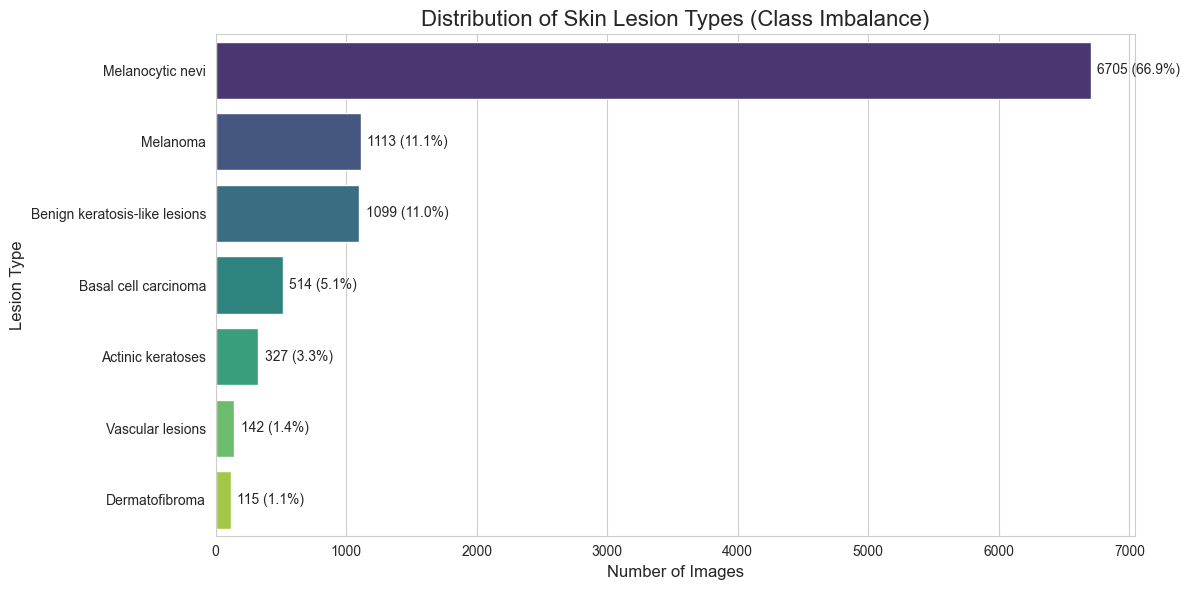


--- INSIGHT ---
Melanoma samples: 1113 out of 10015 (11.1%)
Conclusion: The dataset is heavily imbalanced. We will need Data Augmentation or Weighted Loss to prevent the model from ignoring Melanoma cases.


In [3]:
# 3. Class Distribution Analysis
# ------------------------------

# Count samples per category
class_counts = df['cell_type'].value_counts()

# Plotting
plt.figure(figsize=(12, 6))
ax = sns.barplot(x=class_counts.values, y=class_counts.index, palette="viridis", hue=class_counts.index, legend=False)

plt.title("Distribution of Skin Lesion Types (Class Imbalance)", fontsize=16)
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Lesion Type", fontsize=12)

# Adding counts and percentages to the bars for clarity
total_samples = len(df)
for i, v in enumerate(class_counts.values):
    percentage = v / total_samples * 100
    ax.text(v + 50, i, f"{v} ({percentage:.1f}%)", va='center', fontsize=10)

plt.tight_layout()
plt.show()

# Specific focus on Melanoma (the malignant class we want to detect)
melanoma_count = df[df['dx'] == 'mel'].shape[0]
print(f"\n--- INSIGHT ---")
print(f"Melanoma samples: {melanoma_count} out of {total_samples} ({melanoma_count/total_samples:.1%})")
print("Conclusion: The dataset is heavily imbalanced. We will need Data Augmentation or Weighted Loss to prevent the model from ignoring Melanoma cases.")

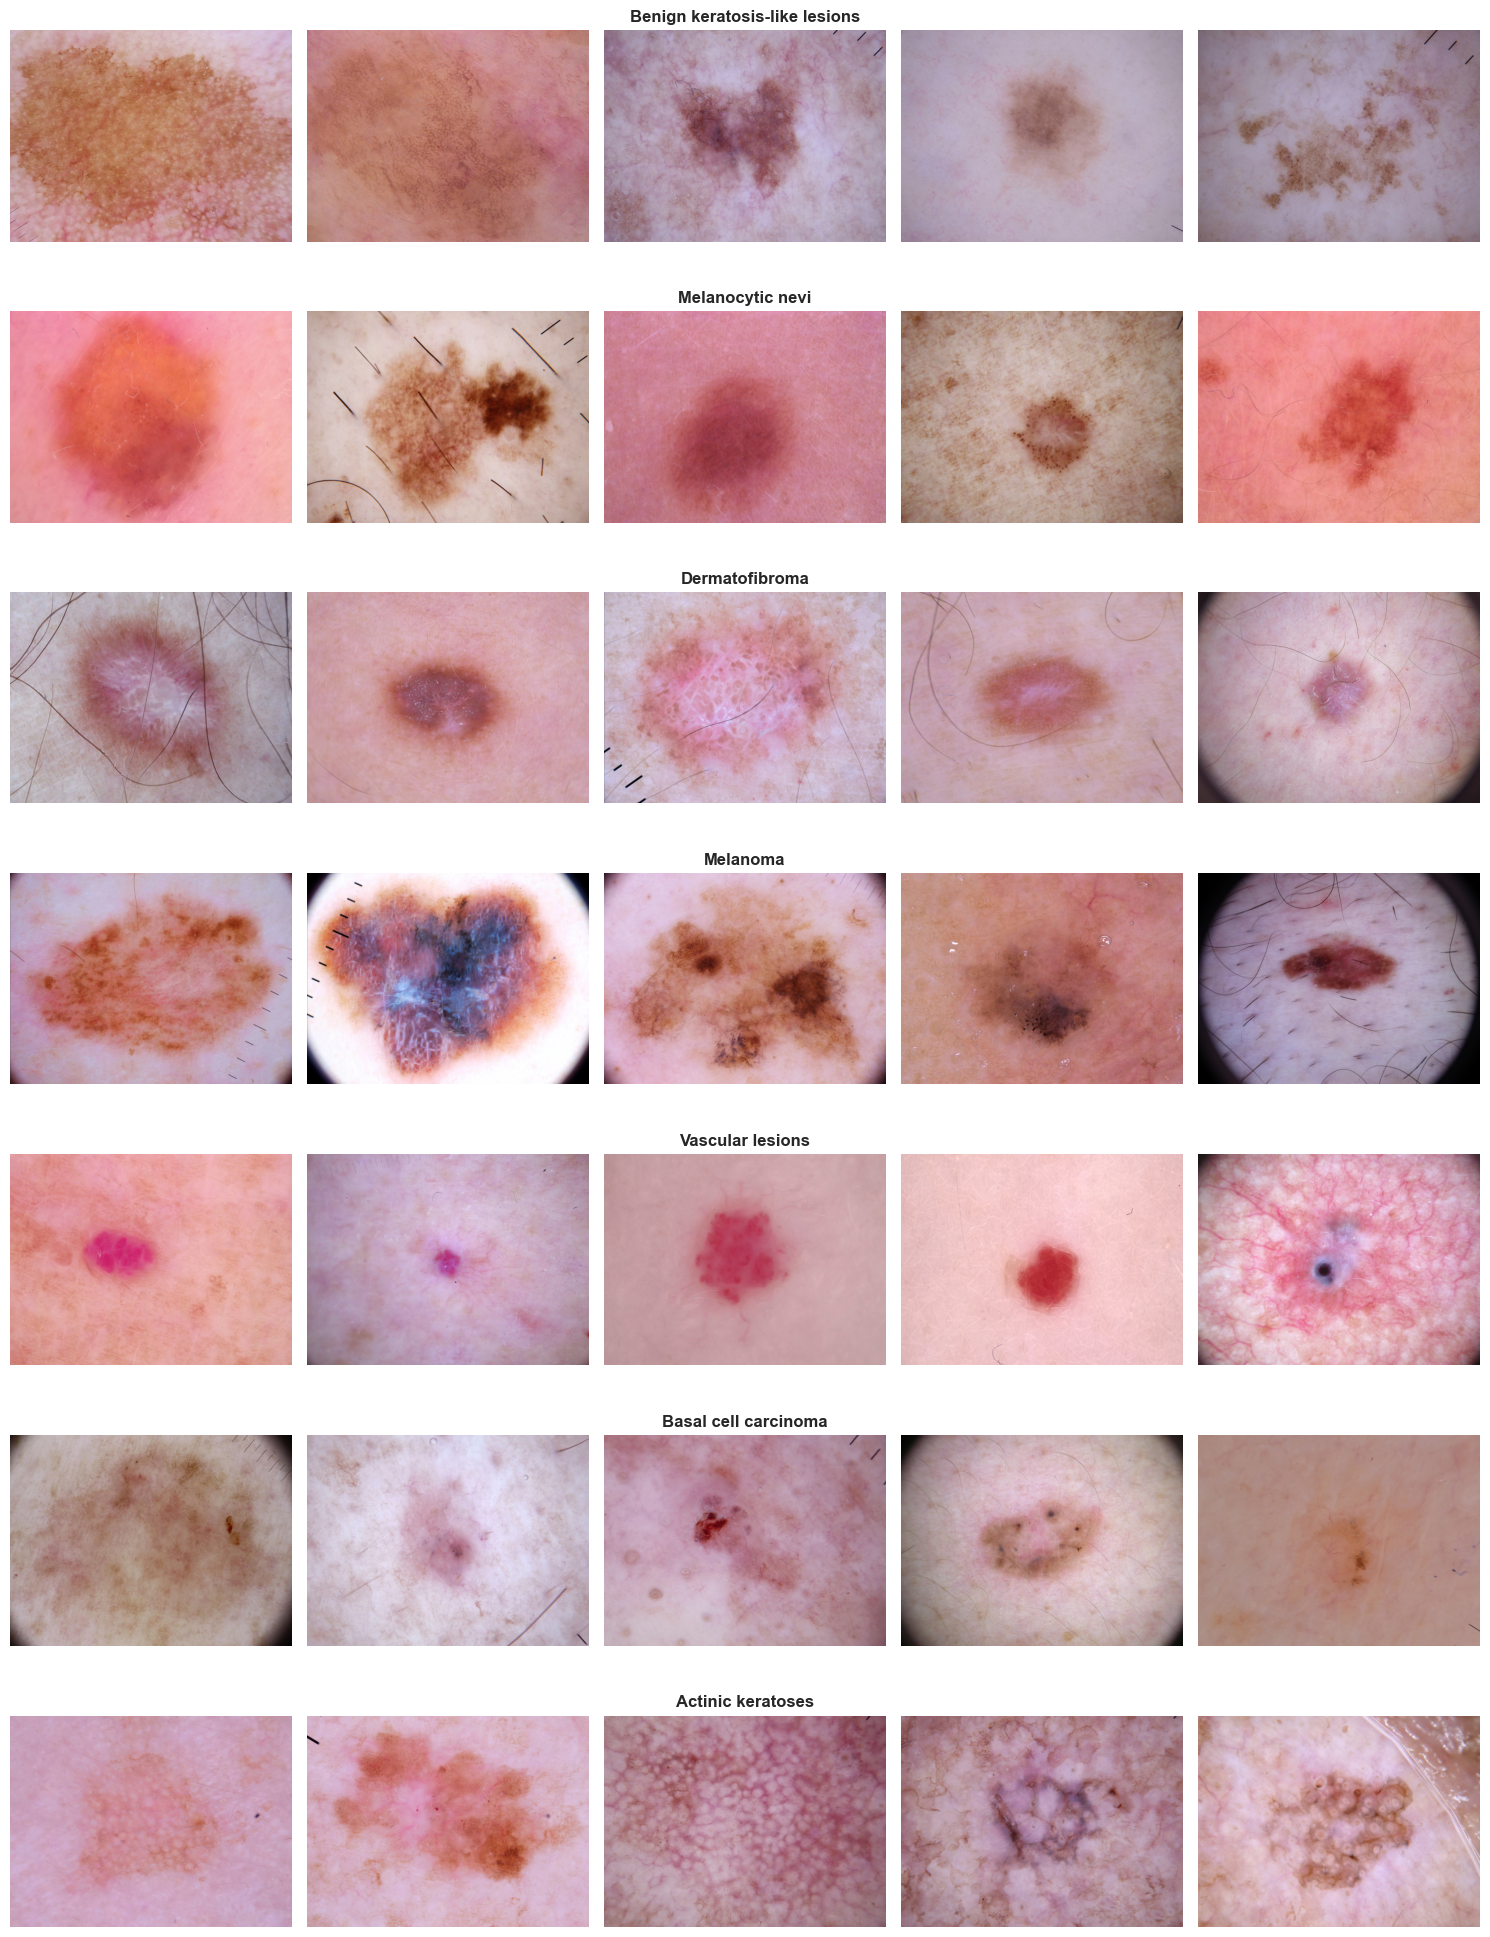

In [4]:
# 4. Visual Inspection of Samples
# -------------------------------
# It's crucial to look at the data to understand intra-class variance.

n_samples = 5
categories = df['cell_type'].unique()

fig, axes = plt.subplots(len(categories), n_samples, figsize=(15, 20))

for i, category in enumerate(categories):
    # Sample n images from this specific category
    sample_df = df[df['cell_type'] == category].sample(n_samples, random_state=42)
    
    for j, (_, row) in enumerate(sample_df.iterrows()):
        ax = axes[i, j]
        img_path = row['path']
        
        try:
            img = Image.open(img_path)
            ax.imshow(img)
            ax.axis('off')
            
            # Add title only on the middle column to avoid clutter
            if j == 2:
                ax.set_title(category, fontsize=12, fontweight='bold')
                
        except Exception as e:
            ax.text(0.5, 0.5, "Image not found", ha='center')

plt.tight_layout()
plt.show()